In [19]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

In [20]:
file_path = "../../datasets/square_image_v15.hdf5"
# file_path = "../../datasets/random/square_random.hdf5"

In [21]:

with h5py.File(file_path, "r") as f:
    print("High level keys: ", f.keys())
    demos = sorted(f["data"].keys())
    print("Number of demonstrations:", len(demos))

    demo = f["data"][demos[0]]
    print("Available observations:", list(demo["obs"].keys()))

    # Load camera images into memory before closing the file
    # print("Location of cube:", demo["obs"]["object"][0])
    agentview_images = demo["obs"]["agentview_image"][:]
    eye_in_hand_images = demo["obs"]["robot0_eye_in_hand_image"][:]
    obj = demo["obs"]["object"][:]
    robot0_eef_pos = demo["obs"]["robot0_eef_pos"][:]
    robot0_eef_quat = demo["obs"]["robot0_eef_quat"][:]

print("Image shape:", agentview_images.shape)
print("Image dtype:", agentview_images.dtype)
# print("Object shape:", demo["obs"]["object"].shape)

print("Object shape:", obj.shape)
print("robot0_eef_pos shape:", robot0_eef_pos.shape)




High level keys:  <KeysViewHDF5 ['data', 'mask']>
Number of demonstrations: 200
Available observations: ['agentview_image', 'object', 'robot0_eef_pos', 'robot0_eef_quat', 'robot0_eef_quat_site', 'robot0_eye_in_hand_image', 'robot0_gripper_qpos', 'robot0_gripper_qvel', 'robot0_joint_acc', 'robot0_joint_pos', 'robot0_joint_pos_cos', 'robot0_joint_pos_sin', 'robot0_joint_vel']
Image shape: (127, 84, 84, 3)
Image dtype: uint8
Object shape: (127, 14)
robot0_eef_pos shape: (127, 3)


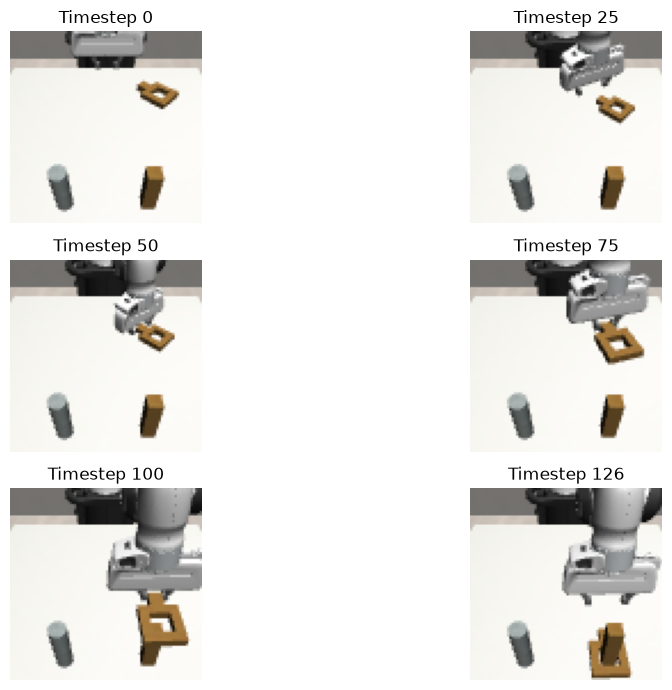

In [22]:
indices = np.linspace(0, len(agentview_images) - 1, 6, dtype=int)

fig, axes = plt.subplots(3, 2, figsize=(12, 7))

for ax, idx in zip(axes.flat, indices):
    ax.imshow(agentview_images[idx])
    ax.set_title(f"Timestep {idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()

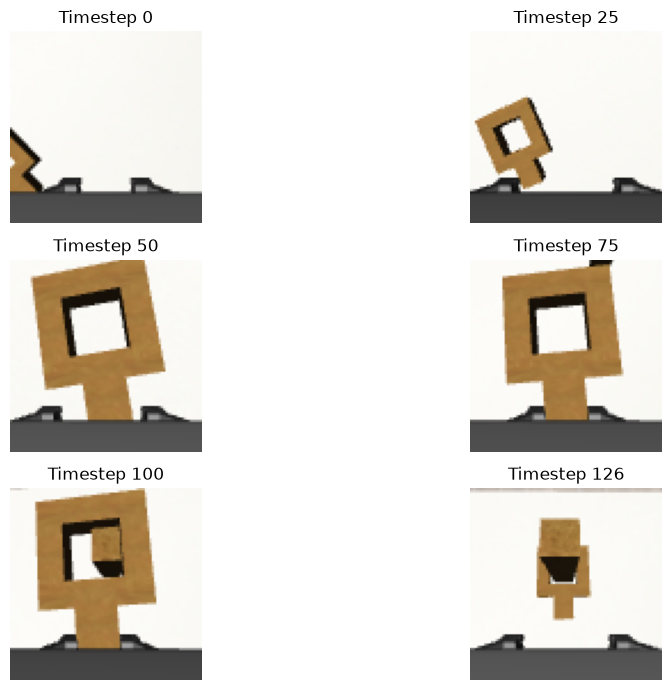

In [23]:
indices = np.linspace(0, len(eye_in_hand_images) - 1, 6, dtype=int)

fig, axes = plt.subplots(3, 2, figsize=(12, 7))

for ax, idx in zip(axes.flat, indices):
    ax.imshow(eye_in_hand_images[idx])
    ax.set_title(f"Timestep {idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [25]:
from robomimic_dataset import RoboMimicDataset

data = RoboMimicDataset(file_path)
print(len(data))
print(data[0].keys())

30154
dict_keys(['observation', 'action_chunk', 'action_mask'])


In [26]:
print(data[0]["observation"].keys())
print(data[0]["observation"]["agent_image"].shape)
print(data[0]["observation"]["wrist_image"].shape)
print(data[0]["observation"]["proprio"].shape)


dict_keys(['agent_image', 'wrist_image', 'proprio'])
torch.Size([3, 84, 84])
torch.Size([3, 84, 84])
torch.Size([9])


In [27]:
print(data[0]["observation"]["proprio"])


tensor([-0.1118,  0.0028,  0.9984,  0.9987,  0.0118,  0.0486,  0.0030,  0.0208,
        -0.0208])


In [28]:
print(data[5]["action_chunk"])

tensor([[ 0.3220,  0.1570, -0.3050, -0.0157,  0.0674,  0.0637, -1.0000],
        [ 0.2010,  0.2710, -0.0980, -0.0145,  0.0569,  0.0855, -1.0000],
        [ 0.2140,  0.2680, -0.2000, -0.0240,  0.0604,  0.1043, -1.0000],
        [ 0.1430,  0.4660, -0.0900, -0.0185,  0.0585,  0.1167, -1.0000],
        [ 0.0390,  0.3860, -0.3730, -0.0022,  0.0465,  0.1269, -1.0000],
        [-0.0020,  0.3570, -0.2430,  0.0135,  0.0405,  0.1420, -1.0000],
        [-0.0440,  0.3740, -0.4530,  0.0290,  0.0393,  0.1552, -1.0000],
        [-0.0520,  0.4190, -0.5540,  0.0467,  0.0431,  0.1691, -1.0000],
        [-0.2100,  0.4140, -0.4530,  0.0608,  0.0446,  0.1749, -1.0000],
        [-0.3090,  0.3280, -0.4350,  0.0572,  0.0354,  0.1837, -1.0000],
        [-0.2530,  0.2880, -0.3690,  0.0575,  0.0279,  0.1922, -1.0000],
        [-0.1980,  0.3230, -0.3010,  0.0525,  0.0345,  0.2082, -1.0000],
        [-0.2830,  0.2100, -0.2340,  0.0362,  0.0417,  0.2211, -1.0000],
        [-0.3050,  0.2540, -0.2860,  0.0191,  0.045

In [29]:
print(data[58]["action_chunk"])
print(data[58]["action_mask"])



tensor([[ 5.5200e-01,  4.4400e-01,  5.0000e-01,  1.6471e-02, -1.3047e-02,
         -8.7803e-02,  1.0000e+00],
        [ 6.9900e-01,  3.0300e-01,  9.1500e-01,  2.4337e-02,  1.2653e-03,
         -1.1916e-01,  1.0000e+00],
        [ 8.4600e-01,  1.1800e-01,  1.0000e+00,  2.6311e-03,  2.5363e-02,
         -1.3969e-01,  1.0000e+00],
        [ 1.0000e+00,  1.0000e-02,  1.0000e+00, -1.0911e-02,  5.7528e-02,
         -1.6515e-01,  1.0000e+00],
        [ 1.0000e+00, -2.5000e-02,  1.0000e+00, -6.7334e-03,  9.8713e-02,
         -1.8670e-01,  1.0000e+00],
        [ 1.0000e+00, -1.6700e-01,  1.0000e+00,  1.0182e-02,  1.2026e-01,
         -2.0707e-01,  1.0000e+00],
        [ 1.0000e+00, -1.3400e-01,  1.0000e+00,  5.7014e-03,  1.2404e-01,
         -2.1700e-01,  1.0000e+00],
        [ 1.0000e+00, -4.4200e-01,  1.0000e+00, -1.5828e-03,  1.2597e-01,
         -2.2064e-01,  1.0000e+00],
        [ 1.0000e+00, -2.7700e-01,  1.0000e+00,  8.3495e-03,  1.2330e-01,
         -2.4214e-01,  1.0000e+00],
        [ 

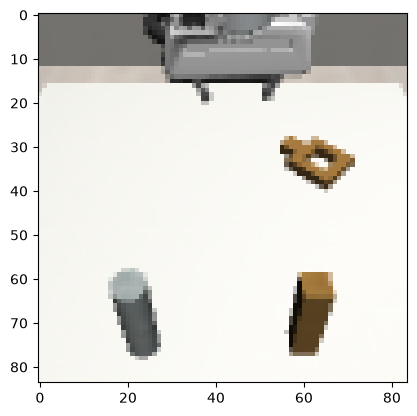

In [30]:
img = data[10]["observation"]["agent_image"]
plt.imshow(img.permute(1,2,0))



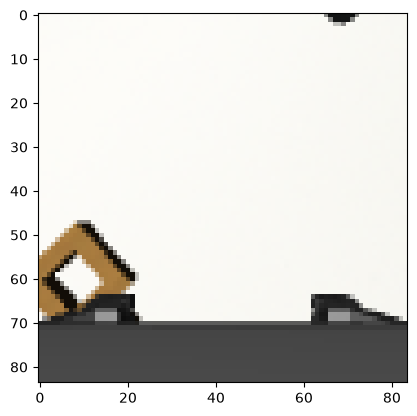

In [31]:
img = data[10]["observation"]["wrist_image"]
plt.imshow(img.permute(1,2,0))


In [32]:
from torch.utils.data import DataLoader

dataloader = DataLoader(data, batch_size=10, shuffle=True)

for batch in dataloader:
    print(batch.keys())
    print(batch["action_chunk"].shape)
    print(batch["observation"].keys())
    print(batch["observation"]["agent_image"].shape)
    break

dict_keys(['observation', 'action_chunk', 'action_mask'])
torch.Size([10, 16, 7])
dict_keys(['agent_image', 'wrist_image', 'proprio'])
torch.Size([10, 3, 84, 84])


In [33]:
print("Object:", obj)
print("robot0_eef_pos:", robot0_eef_pos)

Object: [[ 1.44044378e-02 -1.69802590e-03  1.00457791e+00 ...  0.00000000e+00
   9.16376236e-01 -4.00318116e-01]
 [-2.17939445e-02 -1.71391880e-01  1.14963510e-01 ... -9.60698396e-06
   9.16376236e-01 -4.00318116e-01]
 [-3.21442811e-02 -1.71063983e-01  1.31257580e-01 ... -5.66871420e-05
   9.16376227e-01 -4.00318112e-01]
 ...
 [ 6.94370570e-02 -3.66332449e-03  1.11326866e-01 ... -9.65803547e-04
   9.99883233e-01 -1.32561865e-02]
 [ 7.03964861e-02 -4.26804119e-03  1.19496131e-01 ... -5.07228969e-04
   9.99904684e-01 -1.32563472e-02]
 [ 7.09689174e-02 -5.39698261e-03  1.24428248e-01 ... -2.44049841e-04
   9.99910394e-01 -1.32564296e-02]]
robot0_eef_pos: [[-0.11178995  0.00276081  0.99844004]
 [-0.10014207  0.0038082   1.00760252]
 [-0.09374191  0.00395344  1.01201752]
 [-0.09216025  0.0039238   1.01218231]
 [-0.08932316  0.00357627  1.01121195]
 [-0.08541907  0.00423822  1.00942522]
 [-0.0810345   0.00549486  1.00666456]
 [-0.07715844  0.00774611  1.00448678]
 [-0.07387874  0.01051624  1